# AI Developer Productivity, Task Success, and Emerging Technology Trends📝

![Banner](./assets/banner.jpeg)

## Topic
*What problem are you (or your stakeholder) trying to address?*
📝 <!-- Answer Below -->

As we observe, AI has changed the way developers build software from writing line by line to architect complex solutions, they can work faster and more efficiently. With the way things are going, lots of ideas and creative technologies have been created. Nowadays, developers can use tools like AI models to help generate code, code review, debug errors, create tests, and even architecture design. 

The problem I tried to study is to find out if increased use of AI tools is actually associated with higher developers productivity or if it brings more issues related to additional debugging, verification, and rework.

This project aims to use metrics such as coding time, AI usage, bugs reported, and task success to examine developer productivity and its relationship with AI development tools. In addition, I will look at the model families developers report using and compare coding benchmark scores across selected model versions.

## Project Question
*What specific question are you seeking to answer with this project?*
*This is not the same as the questions you ask to limit the scope of the project.*
📝 <!-- Answer Below -->

I'd like to ask how AI usage is changing software developement in term of developer productivity, developer experience, and technology trends.
The analysis will:
- Analyze how AI usage is related to implementation time, post-review work, perceived effort, and task completion.

- Examine how often developers use AI tools, how trust differs across usage groups, what frustrations current AI users report, and which model families they have used.

- Compare Coding Index scores across selected model versions and discuss these results alongside the model families reported in the survey.

## What would an answer look like?
*What is your hypothesized answer to your question?*
📝 <!-- Answer Below -->

My hypothesis is that the increased use of AI development tools will generally be associated with higher productivity and faster task completion. Along with that, I expect the increased use of AI may introduce additional debugging, verification, or code-quality problems.

Therefore, I think the results will show that AI can improve productivity while also bringing tradeoffs.

Some answers may be:
- Developers with AI usage may complete the initial implementation faster.

- AI usage may affect the amount of time spent making changes after code review.

- Developers who use AI tools more frequently may report higher trust in AI output.

- Higher AI usage may also introduce additional debugging or quality-related concerns.
- Selected model versions may have different coding benchmark scores, even within the same model family.

This project aims to study about the correlation and relationships, rather than claiming that AI directly changes developer productivity. 

## Data Sources

This project will use three data sources:

- METR Developer Productivity Study (CSV) will be used to collect developer productivity which includes tasks completed with and without AI assistance.

- Stack Overflow Developer Survey 2025 (CSV) will be used to examine developers' AI usage, trust, frustrations, and the model families they have used. 

- Artificial Analysis Data API (API) will be used to collect model names, creators, release dates, and Coding Index scores.

The datasets will not be directly merged but instead, their results will be used to compare in the final analysis to provide different perspectives on how AI is affecting software development.

## Approach and Analysis
*What is your approach to answering your project question?*
*How will you use the identified data to answer your project question?*
📝 <!-- Start Discussing the project here; you can add as many code cells as you need -->

- METR Developer Productivity Study: this data source provides a list of developers with AI and non-AI usage. I can use metrics like `implementation time`, `post-review time`, `task completion`, and `perceived effort` to compare productivity between these two groups. Bar charts may be used to support the analysis through visualization.

- Stack Overflow Developer Survey 2025: I will use `AISelect`, `AIAcc`, and `AIFrustration` to examine AI usage frequency, compare trust across usage groups, and identify common frustrations among current AI users. I will also use `AIModelsHaveWorkedWith` to identify the model families developers have used.

- Artificial Analysis API: I will use the Coding Index to compare coding benchmark scores across selected model versions. A bar chart can show how their scores differ. I will discuss these results alongside the survey model usage responses. The survey lists model families, while the API scores specific versions, so I will keep the two results separate.

# Setup and Import Libraries


In [91]:
!pip install python-dotenv matplotlib

In [92]:
# Import libraries
import os
from dotenv import load_dotenv

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import plotly.express as px

# Data Import



### Import METR Data 

In [93]:
metr_df = pd.read_csv("data/raw/osdp.csv")
metr_df.shape

(1134, 14)

In [94]:
metr_df.head()

,id,developerId,treatmentAssignment,status,priorExperience,estimatedTimeWithAI,estimatedTimeWithoutAI,createdAt,lastModified,initialImplementationTime,postReviewImplementationTime,estimatedTimeOtherTreatment,perceivedEffort,isPanelDeveloper
0,47a33fef-793f-429c-98e7-f778bbcc52d5,54,AI-disallowed,complete,4.0,50.0,50.0,2025-08-12,2025-08-13,77.0,30.0,90.0,3.0,True
1,25e419a1-4ceb-4111-98d6-14e9f24d3d72,38,AI-allowed,incomplete,2.0,60.0,70.0,2025-08-12,2025-08-12,24.0,NaN,NaN,NaN,True
2,640fda7c-2b07-4fc3-85f6-b1e347247ba6,3,AI-disallowed,complete,4.0,60.0,60.0,2025-08-12,2025-08-20,188.0,0.0,160.0,2.0,True
3,10df330a-d84c-41d2-8557-b311e54fc289,12,AI-allowed,complete,3.0,330.0,300.0,2025-08-13,2025-11-12,648.0,0.0,500.0,4.0,True
4,edd974a5-04b7-4c7c-994b-51d78eef79de,54,AI-allowed,incomplete,5.0,20.0,20.0,2025-08-13,2025-08-13,25.0,NaN,NaN,4.0,True


In [95]:
metr_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1134 entries, 0 to 1133
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   id                            1134 non-null   str    
 1   developerId                   1134 non-null   int64  
 2   treatmentAssignment           1134 non-null   str    
 3   status                        1134 non-null   str    
 4   priorExperience               1134 non-null   float64
 5   estimatedTimeWithAI           1134 non-null   float64
 6   estimatedTimeWithoutAI        1134 non-null   float64
 7   createdAt                     1134 non-null   str    
 8   lastModified                  1134 non-null   str    
 9   initialImplementationTime     915 non-null    float64
 10  postReviewImplementationTime  861 non-null    float64
 11  estimatedTimeOtherTreatment   868 non-null    float64
 12  perceivedEffort               888 non-null    float64
 13  isPanelDevelop

### Import Stack Overflow Data

Because the original dataset is over 100MB, I couldn't push it to GitHub without setting up GitHub LFS, please download the data source from [Stack Overflow Developer Survey 2025](tps://github.com/StackExchange/Survey/blob/main/packages/archive/2025/results.csv) and rename it to `stackoverflowdata.csv` and move it to `data/raw`

In [96]:
stackoverflow_df = pd.read_csv("data/raw/stackoverflowdata.csv")
stackoverflow_df.shape

/var/folders/5k/dqhlcc4j52q82_012tkcvr8w0000gn/T/ipykernel_79948/362504417.py:1: DtypeWarning: Columns (56: JobSatPoints_15_TEXT, 74: DatabaseHaveEntry, 92: DevEnvHaveEntry, 97: SOTagsHaveEntry, 98: SOTagsWant Entry, 105: OfficeStackWantEntry, 109: CommPlatformHaveEntr, 110: CommPlatformWantEntr, 132: SO_Actions_15_TEXT, 162: AIAgentOrchestration, 165: AIAgentObsWrite) have mixed types. Specify dtype option on import or set low_memory=False.
  stackoverflow_df = pd.read_csv("data/raw/stackoverflowdata.csv")


(49191, 172)

In [97]:
stackoverflow_df.head()

,ResponseId,MainBranch,Age,EdLevel,Employment,EmploymentAddl,WorkExp,LearnCodeChoose,LearnCode,LearnCodeAI,...,AIAgentOrchestration,AIAgentOrchWrite,AIAgentObserveSecure,AIAgentObsWrite,AIAgentExternal,AIAgentExtWrite,AIHuman,AIOpen,ConvertedCompYearly,JobSat
0,1,I am a developer by profession,25-34 years old,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Employed,"Caring for dependents (children, elderly, etc.)",8.0,"Yes, I am not new to coding but am learning ne...",Online Courses or Certification (includes all ...,"Yes, I learned how to use AI-enabled tools for...",...,Vertex AI,NaN,NaN,NaN,ChatGPT,NaN,When I don’t trust AI’s answers,"Troubleshooting, profiling, debugging",61256.0,10.0
1,2,I am a developer by profession,25-34 years old,"Associate degree (A.A., A.S., etc.)",Employed,NaN,2.0,"Yes, I am not new to coding but am learning ne...",Online Courses or Certification (includes all ...,"Yes, I learned how to use AI-enabled tools for...",...,NaN,NaN,NaN,NaN,NaN,NaN,When I don’t trust AI’s answers;When I want to...,All skills. AI is a flop.,104413.0,9.0
2,3,I am a developer by profession,35-44 years old,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)","Independent contractor, freelancer, or self-em...",None of the above,10.0,"Yes, I am not new to coding but am learning ne...",Online Courses or Certification (includes all ...,"Yes, I learned how to use AI-enabled tools for...",...,NaN,NaN,NaN,NaN,ChatGPT;Claude Code;GitHub Copilot;Google Gemini,NaN,When I don’t trust AI’s answers;When I want to...,"Understand how things actually work, problem s...",53061.0,8.0
3,4,I am a developer by profession,35-44 years old,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Employed,None of the above,4.0,"Yes, I am not new to coding but am learning ne...","Other online resources (e.g. standard search, ...","Yes, I learned how to use AI-enabled tools for...",...,NaN,NaN,NaN,NaN,ChatGPT;Claude Code,NaN,When I don’t trust AI’s answers;When I want to...,NaN,36197.0,6.0
4,5,I am a developer by profession,35-44 years old,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)","Independent contractor, freelancer, or self-em...","Caring for dependents (children, elderly, etc.)",21.0,"No, I am not new to coding and did not learn n...",NaN,"Yes, I learned how to use AI-enabled tools for...",...,NaN,NaN,NaN,NaN,NaN,NaN,When I don’t trust AI’s answers,"critical thinking, the skill to define the tas...",60000.0,7.0


In [98]:
stackoverflow_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 49191 entries, 0 to 49190
Columns: 172 entries, ResponseId to JobSat
dtypes: float64(52), int64(1), str(119)
memory usage: 64.6 MB


### Import Data From Artificial Analysis API


For this part, I will use the [Artificial Analysis Data API](https://artificialanalysis.ai/data-api/docs) to collect model names, creators, release dates, and Coding Index scores. The free endpoint returns JSON.

I use `ARTIFICIAL_ANALYSIS_API_KEY` set in .env file. The code will read all pages and keep the retrieval date in `model_scores_df`.

The Coding Index describes performance on coding benchmarks. It does not measure the time a developer spends coding.


In [99]:
# Import model benchmark data from Artificial Analysis.
load_dotenv(".env")
aa_api_key = os.getenv("ARTIFICIAL_ANALYSIS_API_KEY", "")
if not aa_api_key:
    raise ValueError("An Artificial Analysis API key is required.")
url = "https://artificialanalysis.ai/api/v2/language/models/free"

model_records = []
page = 1

# Fetch all pages of model benchmark data
while True:
    response = requests.get(
        url,
        headers={"x-api-key": aa_api_key},
        params={"page": page},
        timeout=30
    )
    response.raise_for_status()
    data = response.json()
    model_records.extend(data["data"])

    if not data["pagination"]["has_more"]:
        break
    page += 1

model_scores_df = pd.json_normalize(model_records)
model_scores_df["retrieved_at"] = pd.Timestamp.now(tz="UTC")
model_scores_df.to_json(
    "data/raw/artificial_analysis_models.json",
    orient="records",
    date_format="iso"
)
model_scores_df.head()


,id,name,slug,release_date,artificial_analysis_intelligence_index_cost,model_creator.id,model_creator.name,evaluations.artificial_analysis_intelligence_index,evaluations.artificial_analysis_coding_index,evaluations.artificial_analysis_agentic_index,...,pricing.price_1m_output_tokens,pricing.price_1m_cache_hit_tokens,pricing.price_1m_cache_write_tokens,performance.median_output_tokens_per_second,performance.median_time_to_first_token_seconds,performance.median_time_to_first_answer_token_seconds,performance.median_end_to_end_response_time_seconds,artificial_analysis_intelligence_index_cost.total_cost,artificial_analysis_intelligence_index_cost.cost_per_task.total_cost,retrieved_at
0,0081ab31-d10a-44a0-a10d-eee5533fec65,GLM-4.5V (Non-reasoning),glm-4-5v,2025-08-11,NaN,67437eb6-7dc1-4e93-befd-22c8b8ec2065,Z AI,6.7,NaN,NaN,...,1.80,0.1100,NaN,58.09,3.22,3.22,11.83,NaN,NaN,2026-10-20 20:44:12.287142+00:00
1,0097ebf5-124f-42f6-9463-33b00e711f03,Gemini 3.5 Flash (High),gemini-3-5-flash,2026-05-19,NaN,faddc6d9-2c14-445f-9b28-56726f59c793,Google,32.6,70.1,26.0,...,9.00,0.1500,NaN,207.73,15.48,15.48,17.89,4222.12,3.6937,2026-10-20 20:44:12.287142+00:00
2,00f1248e-78e3-4230-8dc8-5e13ba8645e2,MiMo-V2.5-Pro (Reasoning),mimo-v2-5-pro,2026-04-22,NaN,5147c8b4-61d5-4070-9324-8adf8aa144c2,Xiaomi,26.0,60.2,21.3,...,0.87,0.0036,NaN,41.71,2.28,50.23,62.21,138.26,0.0541,2026-10-20 20:44:12.287142+00:00
3,0121d27b-5b8a-4901-8684-80589cc6d40d,JT-35B-Flash,jt-35b-flash,2026-05-14,NaN,7e7b7290-eacc-420e-a35f-7c8eb4e5205d,China Mobile,18.7,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2026-10-20 20:44:12.287142+00:00
4,01459872-433a-4ab2-8e99-7083162172eb,GPT-6 Sol (Low),gpt-6-sol-low,2026-09-22,NaN,e67e56e3-15cd-43db-b679-da4660a69f41,OpenAI,34.2,NaN,NaN,...,10.00,0.2000,2.5,100.87,1.44,1.44,6.40,268.73,0.1328,2026-10-20 20:44:12.287142+00:00


In [100]:
model_scores_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 706 entries, 0 to 705
Data columns (total 27 columns):
 #   Column                                                                Non-Null Count  Dtype              
---  ------                                                                --------------  -----              
 0   id                                                                    706 non-null    str                
 1   name                                                                  706 non-null    str                
 2   slug                                                                  706 non-null    str                
 3   release_date                                                          706 non-null    str                
 4   artificial_analysis_intelligence_index_cost                           0 non-null      float64            
 5   model_creator.id                                                      706 non-null    str                
 6   model_creator

# Data Cleaning and Initial EDA

For this part, I will prepare each dataset separately. I will check for missing values, duplicate records, and other abnormal values then decide how to handle them based on the analysis.


### Prepare METR Data

At first, I want to see a overview of METR dataset by using describe() 

In [101]:
metr_df.describe()

,developerId,priorExperience,estimatedTimeWithAI,estimatedTimeWithoutAI,initialImplementationTime,postReviewImplementationTime,estimatedTimeOtherTreatment,perceivedEffort
count,1134.000000,1134.000000,1134.000000,1134.000000,915.000000,861.000000,868.000000,888.000000
mean,23.450617,2.780423,131.135802,188.480600,159.288525,20.333333,192.247696,2.628378
std,16.528846,1.280696,160.985489,230.288984,209.272617,68.836893,306.830761,1.099023
min,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,1.000000
25%,9.000000,2.000000,40.000000,60.000000,39.000000,0.000000,40.000000,2.000000
50%,22.000000,3.000000,90.000000,120.000000,87.000000,0.000000,90.000000,3.000000
75%,33.000000,4.000000,180.000000,240.000000,189.500000,13.000000,220.000000,3.000000
max,57.000000,5.000000,1800.000000,1900.000000,1685.000000,1134.000000,3600.000000,5.000000


I see some abnormal values on time related columns. For example, `initialImplementationTime` can be right-skewed because its mean value is 159.29, but median is 87, and max is 1685. Mean is much higher than median, there may be some long time tasks making mean value higher. But I'll first check missing values and duplicated values and then will check the describe statistical again.

In [102]:
metr_df.isnull().sum()


id                                0
developerId                       0
treatmentAssignment               0
status                            0
priorExperience                   0
estimatedTimeWithAI               0
estimatedTimeWithoutAI            0
createdAt                         0
lastModified                      0
initialImplementationTime       219
postReviewImplementationTime    273
estimatedTimeOtherTreatment     266
perceivedEffort                 246
isPanelDeveloper                  0
dtype: int64

Four columns have missing values: `initialImplementationTime`, `postReviewImplementationTime`, `estimatedTimeOtherTreatment`, and `perceivedEffort`.

Next, I will check which task statuses have these missing values. This will help me decide which tasks to use for each comparison.


In [103]:
metr_df["status"].value_counts()

status
complete      828
incomplete    244
ditched        57
corrupted       3
cheating        2
Name: count, dtype: int64

In [104]:
missing_fields = metr_df.columns[metr_df.isnull().any()]

# Filter to only includes rows with missing values
metr_missing_by_status = metr_df.groupby('status')[missing_fields].apply(lambda x: x.isnull().sum())
metr_missing_by_status['task_count'] = metr_df.groupby('status').size()
metr_missing_by_status


,initialImplementationTime,postReviewImplementationTime,estimatedTimeOtherTreatment,perceivedEffort,task_count
status,,,,,
cheating,0,0,0,0,2
complete,0,0,0,0,828
corrupted,0,0,0,0,3
ditched,46,50,49,49,57
incomplete,173,223,217,197,244


All 828 completed tasks have values in these four columns. The missing values only appear in incomplete or ditched tasks.

Next, I will check for duplicate task IDs.


In [105]:
metr_df["id"].duplicated().sum()

np.int64(0)

There are no duplicate task IDs, so no records need to be removed at this step.

I will keep 3 statuses (complete, incomplete, and ditched tasks) for the task completion analysis and exclude 5 records labeled cheating or corrupted. For time and effort comparisons, I will use completed tasks, any analysis established for this dataframe will not represent the rest of the dataset. I will keep the original DataFrame and will not fill missing values with 0.

In [106]:
# Keep the three status for the status comparison
metr_status_df = metr_df[metr_df['status'].isin(['complete','ditched','incomplete'])].copy()

# Keep completed tasks for time and effort comparison
metr_complete_df = metr_status_df[metr_status_df['status'] == 'complete'].copy()

In [107]:
metr_complete_df.describe()

,developerId,priorExperience,estimatedTimeWithAI,estimatedTimeWithoutAI,initialImplementationTime,postReviewImplementationTime,estimatedTimeOtherTreatment,perceivedEffort
count,828.000000,828.000000,828.000000,828.000000,828.000000,828.000000,828.000000,828.000000
mean,23.376812,2.878019,120.320048,170.910628,160.237923,20.384058,194.664251,2.608696
std,16.517274,1.296764,150.517922,212.734865,211.621568,69.459982,311.473393,1.099201
min,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,1.000000
25%,9.000000,2.000000,30.000000,45.000000,37.000000,0.000000,40.000000,2.000000
50%,24.000000,3.000000,70.000000,120.000000,86.000000,0.000000,90.000000,3.000000
75%,33.000000,4.000000,150.000000,212.500000,193.250000,13.250000,220.000000,3.000000
max,57.000000,5.000000,1200.000000,1800.000000,1685.000000,1134.000000,3600.000000,5.000000


These values are still a little abnormal, so I will sketch a histogram to check the distribution of `initialImplementationTime`

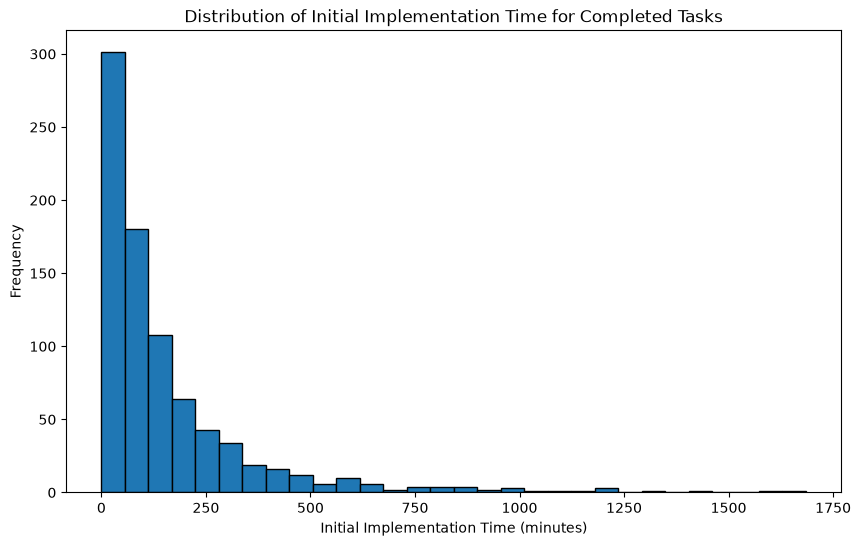

In [108]:
fig = plt.figure(figsize=(10, 6))
plt.hist(metr_complete_df["initialImplementationTime"], bins=30, edgecolor='black')
plt.xlabel("Initial Implementation Time (minutes)")
plt.ylabel("Frequency")
plt.title("Distribution of Initial Implementation Time for Completed Tasks")

plt.show()

From this chart, I can say the `initialImplementationTime` is right-skewed when most values concentrates between 0-500, while some tasks have implementation time up to 1700 minutes, it creates a long right tail.

There are also some potential outliers for time above 1000, which may affect `initialImplementationTime` but they may not be removed from the dataframe since some complex tasks may take longer time to complete.

### Prepare Stack Overflow Data


I will keep `ResponseId` and `AIModelsHaveWorkedWith` in `stackoverflow_models_df` for the model usage question. I will count the available model answers later in the EDA.


In [ ]:
stackoverflow_models_df = stackoverflow_df[
    ["ResponseId", "AIModelsHaveWorkedWith"]
].copy()
model_counts = (
    stackoverflow_models_df["AIModelsHaveWorkedWith"]
    .str.split(";")
    .explode()
    .value_counts()
)

model_counts

AIModelsHaveWorkedWith
openAI GPT (chatbot models)              13424
Anthropic: Claude Sonnet                  7063
Gemini (Flash general purpose models)     5823
openAI Reasoning models                   5716
openAI Image generating models            4395
Gemini (Pro Reasoning models)             4221
DeepSeek (R- Reasoning models)            3848
Meta Llama (all models)                   2941
DeepSeek (V- General purpose models)      2363
X Grok models                             1839
Mistral AI models                         1712
Perplexity Sonar models                   1250
Alibaba Cloud Qwen models                  864
Microsoft Phi-4 models                     833
Amazon Titan models                        283
Cohere: Command A                          139
Reka (Flash 3 or other Reka models)         57
Name: count, dtype: int64

In [122]:
stackoverflow_models_df.duplicated().sum()

np.int64(0)

No duplicate ResponseId values were found, so no responses were removed at this step.

I will keep the 10 columns selected for the project. The usage, trust, and frustration questions will focus on `AISelect`, `AIAcc`, and `AIFrustration`. `AISent` and `AIComplex` will be used to answer further questions on people who use AI frequently and somewhat trust it to see how they think about it


In [110]:
# Keep the columns used in the analysis.
col_used = [
    "Employment",
    "DevType",
    "WorkExp",
    "YearsCode",
    "LanguageHaveWorkedWith",
    "AISelect",
    "AISent",
    "AIAcc",
    "AIComplex",
    "AIFrustration"
]

stackoverflow_df = stackoverflow_df[col_used].copy()
stackoverflow_df.head()

,Employment,DevType,WorkExp,YearsCode,LanguageHaveWorkedWith,AISelect,AISent,AIAcc,AIComplex,AIFrustration
0,Employed,"Developer, mobile",8.0,14.0,Bash/Shell (all shells);Dart;SQL,"Yes, I use AI tools monthly or infrequently",Indifferent,Neither trust nor distrust,Bad at handling complex tasks,"AI solutions that are almost right, but not quite"
1,Employed,"Developer, back-end",2.0,10.0,Java,"Yes, I use AI tools weekly",Indifferent,Neither trust nor distrust,Bad at handling complex tasks,"AI solutions that are almost right, but not qu..."
2,"Independent contractor, freelancer, or self-em...","Developer, front-end",10.0,12.0,Dart;HTML/CSS;JavaScript;TypeScript,"Yes, I use AI tools daily",Favorable,Somewhat trust,Neither good or bad at handling complex tasks,"AI solutions that are almost right, but not qu..."
3,Employed,"Developer, back-end",4.0,5.0,Java;Kotlin;SQL,"Yes, I use AI tools weekly",Favorable,Somewhat trust,Bad at handling complex tasks,"AI solutions that are almost right, but not qu..."
4,"Independent contractor, freelancer, or self-em...",Engineering manager,21.0,22.0,C;C#;C++;Delphi;HTML/CSS;Java;JavaScript;Lua;P...,"Yes, I use AI tools weekly",Favorable,Neither trust nor distrust,"Good, but not great at handling complex tasks","AI solutions that are almost right, but not quite"


Next, I will check which of the selected columns have missing values.


In [111]:
stackoverflow_df.isna().sum()

Employment                  852
DevType                    5511
WorkExp                    6298
YearsCode                  6149
LanguageHaveWorkedWith    17520
AISelect                  15471
AISent                    15724
AIAcc                     15894
AIComplex                 15908
AIFrustration             17669
dtype: int64

I will remove rows with missing values across the 5 columns `AISelect`, `AISent`, `AIAcc`, `AIComplex`, and `AIFrustration`. Along with that, I will split into 3 different dataframe for each analysis, that way I can preverse as many values as possble for later analysis.



In [119]:
# Keep available responses for AI usage analysis.
stackoverflow_usage_df = stackoverflow_df[["AISelect"]].dropna().copy()

# Keep responses to compare trust across usage groups.
stackoverflow_trust_df = stackoverflow_df[
    ["AISelect", "AIAcc"]
].dropna().copy()

# Keep responses for frustration analysis.
stackoverflow_frustration_df = stackoverflow_df[
    ["AISelect", "AIFrustration"]
].dropna().copy()

In [121]:
stackoverflow_usage_df.value_counts()

AISelect                                   
Yes, I use AI tools daily                      15883
Yes, I use AI tools weekly                      5958
No, and I don't plan to                         5454
Yes, I use AI tools monthly or infrequently     4628
No, but I plan to soon                          1797
Name: count, dtype: int64

### Prepare Artificial Analysis Data

For Artificial Analysis data, I will keep the model `name`, `creator`, `release_date`, `coding_index`, and `retrieval_date`. I will rename `evaluations.artificial_analysis_coding_index` to `coding_index` and models without a score will be left out of the benchmark comparison.


In [113]:
col_used = ["name",
            "model_creator.name",
            "evaluations.artificial_analysis_coding_index",
            "release_date",
            "retrieved_at"
        ]

model_scores_df = model_scores_df[col_used].copy()
model_scores_df.head()

,name,model_creator.name,evaluations.artificial_analysis_coding_index,release_date,retrieved_at
0,GLM-4.5V (Non-reasoning),Z AI,NaN,2025-08-11,2026-10-20 20:44:12.287142+00:00
1,Gemini 3.5 Flash (High),Google,70.1,2026-05-19,2026-10-20 20:44:12.287142+00:00
2,MiMo-V2.5-Pro (Reasoning),Xiaomi,60.2,2026-04-22,2026-10-20 20:44:12.287142+00:00
3,JT-35B-Flash,China Mobile,NaN,2026-05-14,2026-10-20 20:44:12.287142+00:00
4,GPT-6 Sol (Low),OpenAI,NaN,2026-09-22,2026-10-20 20:44:12.287142+00:00


Next, I will rename column to `coding_index` and remove missing values from `coding_index`.

In [114]:
model_scores_df= model_scores_df.rename(columns={"evaluations.artificial_analysis_coding_index": "coding_index"})

In [115]:
model_scores_df.isna().sum()
model_scores_df = model_scores_df.dropna().copy()

I will check duplicated values

In [116]:
model_scores_df.duplicated().sum()

np.int64(0)

Since this benchmark comparison is based on the 2025 survey data, I will only include AI models with a release_date on or before December 31, 2025.

In [117]:
model_scores_df = model_scores_df[model_scores_df['release_date']<="2025-12-31"].copy()
model_scores_df.info()

<class 'pandas.DataFrame'>
Index: 76 entries, 12 to 680
Data columns (total 5 columns):
 #   Column              Non-Null Count  Dtype              
---  ------              --------------  -----              
 0   name                76 non-null     str                
 1   model_creator.name  76 non-null     str                
 2   coding_index        76 non-null     float64            
 3   release_date        76 non-null     str                
 4   retrieved_at        76 non-null     datetime64[us, UTC]
dtypes: datetime64[us, UTC](1), float64(1), str(3)
memory usage: 3.6 KB


# Exploratory Data Analysis

In this section, I'll start exploring the chosen dataset including 

## Stack Overflow Data


### Stack Overflow: AI Usage Frequency
In this section, I will examine how frequently developers use AI tools by counting the responses in each `AISelect` category in `stackoverflow_usage_df`.

In [134]:
AI_counts = stackoverflow_usage_df["AISelect"].value_counts()
fig = px.bar(AI_counts, x=AI_counts.index, y=AI_counts.values, labels={'x':'AI Usage', 'y':'Count'}, title='AI Usage Distribution')

# Add percentage of each category
fig.update_traces(
    customdata=(AI_counts.values / AI_counts.values.sum() * 100).round(2),
    hovertemplate='%{x}: %{y} (%{customdata}%)'
)
fig.show()

About 15883 individuals use AI tools daily accounts for 47.1% of the total. Overall, 78,5% of those who answered this question reported using AI tools daily, weekly or infrequently. About 22% which is a small amount of responders saying they either plan to use AI tools in the future or don't even plan to use it.

## Resources and References
*What resources and references have you used for this project?*
📝 <!-- Answer Below -->

[Open Source Developer Productivity](https://github.com/METR/Measuring-Late-2025-AI-on-OSS-Devs)

[Stack Overflow Developer Survey](https://github.com/StackExchange/Survey)

[Artificial Analysis](https://artificialanalysis.ai/)

[Artificial Analysis Data API documentation](https://artificialanalysis.ai/data-api/docs)

## AI Use Disclosure

I used AI tools to refine project scope and data analysis ideas, improve written explanations. I also used AI to help compare my project scope with the available datasets to ensure the data I selected could actually help answer the questions. I reviewed the final analysis, interpretations, and conclusions myself.

In [118]:
# ⚠️ Make sure you run this cell at the end of your notebook before every submission!
!jupyter nbconvert --to python source.ipynb

[NbConvertApp] Converting notebook source.ipynb to python
[NbConvertApp] Writing 13069 bytes to source.py
